# Processing BIOMASS Level-1a and Level-1c data

This tutorial reads a local BIOMASS Level-1c Standard STA product (the same workflow also supports Level-1a SCS) and builds a lazy polarimetric processing pipeline:

1. reconstruct the scattering matrix with `open_biomass_l1ac`;
2. convert it to a `T3` coherency matrix;
3. multilook to approximately square pixels in SAR geometry;
4. apply the polarimetric Refined Lee speckle filter; and
5. compute and display the H/A/Alpha decomposition.

In [1]:
from pathlib import Path

import dask
import matplotlib.pyplot as plt
from dask.diagnostics import ProgressBar

from polsarpro.decompositions import h_a_alpha
from polsarpro.io import open_biomass_l1ac
from polsarpro.speckle_filters import refined_lee
from polsarpro.util import S_to_T3, multilook, pauli_rgb

## Open a BIOMASS product

Point `product_path` to an unzipped L1a `S[123]_SCS__1S` or L1c `S[123]_STA__1S` product directory. Each L1c directory contains one acquisition registered to a primary image, rather than the complete stack. The reader finds the amplitude and phase rasters under `measurement/`, reconstructs the four complex channels, and keeps them lazy using Dask.

In [2]:
product_path = Path(
    "/data/psp/test_files/"
    "BIO_S2_STA__1S_20261024T040905_20261024T040925_"
    "T_G01_M05_C07_T017_F296_02_E01W8B"
)

S = open_biomass_l1ac(product_path, chunks={"y": 900, "x": 600})
print(S)

<xarray.Dataset> Size: 1GB
Dimensions:  (y: 20782, x: 1567)
Coordinates:
  * y        (y) int64 166kB 0 1 2 3 4 5 ... 20776 20777 20778 20779 20780 20781
  * x        (x) int64 13kB 0 1 2 3 4 5 6 ... 1560 1561 1562 1563 1564 1565 1566
Data variables:
    hh       (y, x) complex64 261MB dask.array<chunksize=(900, 600), meta=np.ndarray>
    hv       (y, x) complex64 261MB dask.array<chunksize=(900, 600), meta=np.ndarray>
    vh       (y, x) complex64 261MB dask.array<chunksize=(900, 600), meta=np.ndarray>
    vv       (y, x) complex64 261MB dask.array<chunksize=(900, 600), meta=np.ndarray>
Attributes:
    poltype:      S
    description:  Scattering matrix


## Convert to a coherency matrix

In [3]:
T3 = S_to_T3(S)
print(T3)

<xarray.Dataset> Size: 1GB
Dimensions:  (y: 20782, x: 1567)
Coordinates:
  * y        (y) int64 166kB 0 1 2 3 4 5 ... 20776 20777 20778 20779 20780 20781
  * x        (x) int64 13kB 0 1 2 3 4 5 6 ... 1560 1561 1562 1563 1564 1565 1566
Data variables:
    m11      (y, x) float32 130MB dask.array<chunksize=(900, 600), meta=np.ndarray>
    m22      (y, x) float32 130MB dask.array<chunksize=(900, 600), meta=np.ndarray>
    m33      (y, x) float32 130MB dask.array<chunksize=(900, 600), meta=np.ndarray>
    m12      (y, x) complex64 261MB dask.array<chunksize=(900, 600), meta=np.ndarray>
    m13      (y, x) complex64 261MB dask.array<chunksize=(900, 600), meta=np.ndarray>
    m23      (y, x) complex64 261MB dask.array<chunksize=(900, 600), meta=np.ndarray>
Attributes:
    poltype:      T3
    description:  Coherency matrix (3x3)


## Apply azimuth multilooking

The range and azimuth sampling is approximately 19.8 m and 6.7 m. Three azimuth looks and one range look give approximately square 20.1 m by 19.8 m pixels in SAR geometry.

In [4]:
T3_multilooked = multilook(
    T3, dim_az=3, dim_rg=1
)
print(T3_multilooked)

<xarray.Dataset> Size: 391MB
Dimensions:  (y: 6927, x: 1567)
Coordinates:
  * y        (y) float64 55kB 1.0 4.0 7.0 10.0 ... 2.077e+04 2.078e+04 2.078e+04
  * x        (x) float64 13kB 0.0 1.0 2.0 3.0 ... 1.564e+03 1.565e+03 1.566e+03
Data variables:
    m11      (y, x) float32 43MB dask.array<chunksize=(300, 600), meta=np.ndarray>
    m22      (y, x) float32 43MB dask.array<chunksize=(300, 600), meta=np.ndarray>
    m33      (y, x) float32 43MB dask.array<chunksize=(300, 600), meta=np.ndarray>
    m12      (y, x) complex64 87MB dask.array<chunksize=(300, 600), meta=np.ndarray>
    m13      (y, x) complex64 87MB dask.array<chunksize=(300, 600), meta=np.ndarray>
    m23      (y, x) complex64 87MB dask.array<chunksize=(300, 600), meta=np.ndarray>
Attributes:
    poltype:      T3
    description:  Coherency matrix (3x3)


## Apply the Refined Lee filter

In [5]:
T3_filtered = refined_lee(
    T3_multilooked,
    window_size=7,
    num_looks= 3,
)

## Apply H/A/Alpha

The Refined Lee result is already spatially filtered, so the decomposition uses a 1 × 1 boxcar to avoid adding another averaging step.

In [6]:
haa = h_a_alpha(
    T3_filtered,
    boxcar_size=[1, 1],
    flags=("entropy", "anisotropy", "alpha"),
)

## Make RGB visuals for intermediate products

In [7]:
rgb_multilooked = pauli_rgb(T3_multilooked)
rgb_filtered = pauli_rgb(T3_filtered)

## Compute results

The processing graph is evaluated only here. Computing the two Pauli images and the decomposition together allows Dask to share upstream work.

In [8]:
with ProgressBar():
    rgb_multilooked, rgb_filtered, haa = dask.compute(
        rgb_multilooked, rgb_filtered, haa
    )

[########################################] | 100% Completed | 52.94 s


## Display the results

First compare Pauli RGB images before and after speckle filtering.

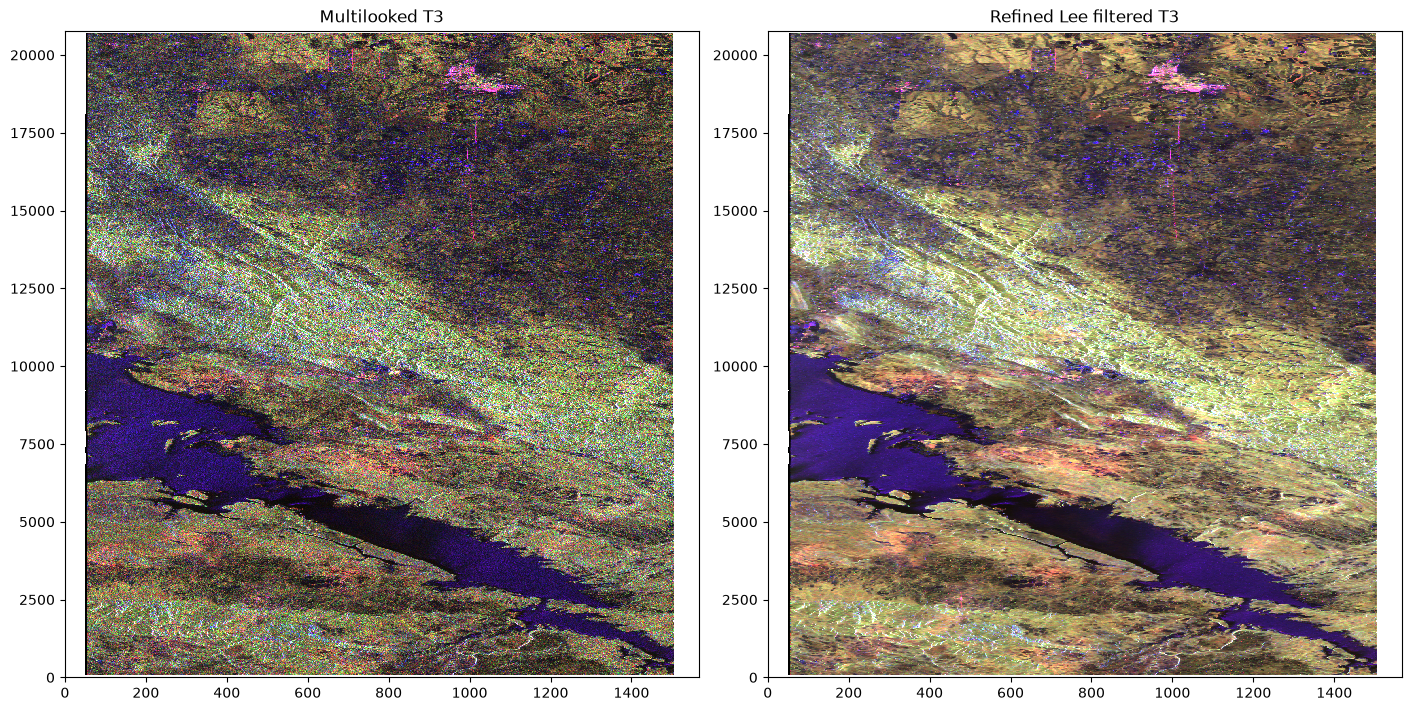

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
rgb_multilooked.plot.imshow(ax=axes[0], rgb="band", add_labels=False)
rgb_filtered.plot.imshow(ax=axes[1], rgb="band", add_labels=False)
axes[0].set_title("Multilooked T3")
axes[1].set_title("Refined Lee filtered T3")
plt.show()

Finally display entropy, anisotropy, and mean alpha angle.

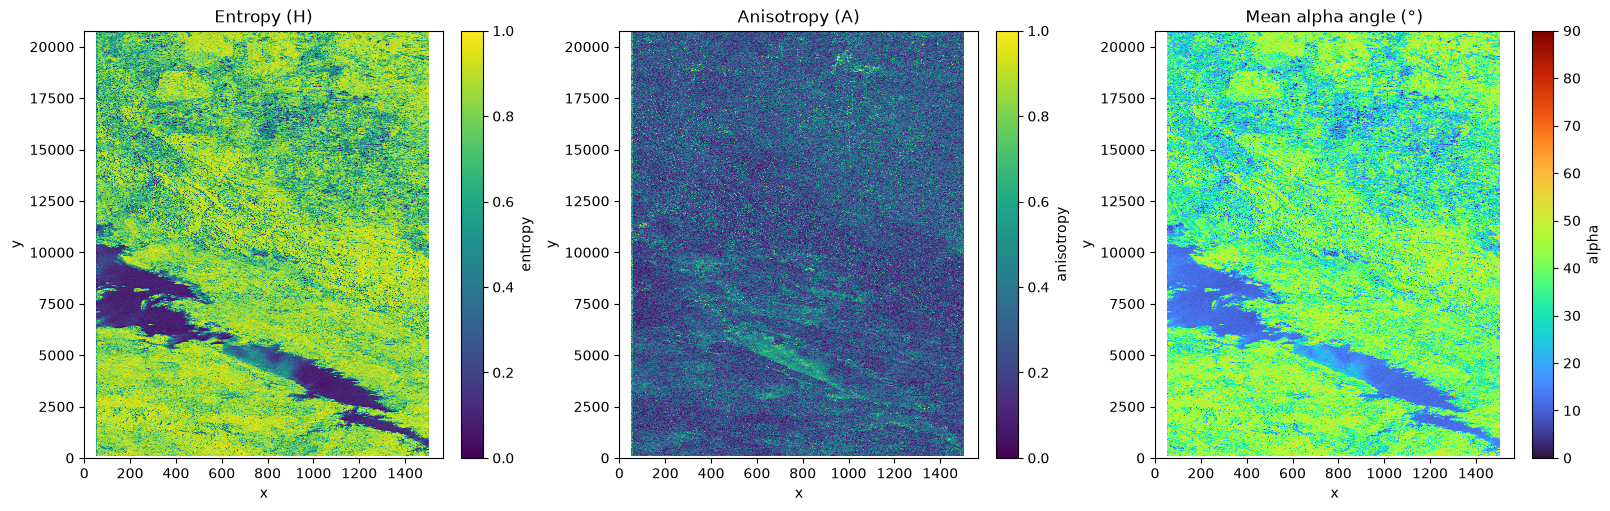

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
haa.entropy.plot.imshow(ax=axes[0], vmin=0, vmax=1, cmap="viridis")
haa.anisotropy.plot.imshow(ax=axes[1], vmin=0, vmax=1, cmap="viridis")
haa.alpha.plot.imshow(ax=axes[2], vmin=0, vmax=90, cmap="turbo")
axes[0].set_title("Entropy (H)")
axes[1].set_title("Anisotropy (A)")
axes[2].set_title("Mean alpha angle (°)")
plt.show()